#### **DataStats - Bacteria Genome** 

In [1]:
# RETREIVAL DATA: 11/12/2024
# SOURCE: NCBI
# SUMMARY: https://ftp.ncbi.nih.gov/genomes/genbank/bacteria/assembly_summary.txt
# SEQUENCE COUNT: 50776
# ORGANISME COUNTS: 14582
# NUCLEOTIDE COUNTS: 216557276627.0
# CDS COUNTS: 195404346

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
assembly_summary = pd.read_csv('./Data/assembly_summary.txt', sep='\t', skiprows=1)
assembly_summary.head(5)

/tmp/ipykernel_158040/760543631.py:3: DtypeWarning: Columns (5,6,34,35,36) have mixed types. Specify dtype option on import or set low_memory=False.
  assembly_summary = pd.read_csv('./Data/assembly_summary.txt', sep='\t', skiprows=1)


,#assembly_accession,bioproject,biosample,wgs_master,refseq_category,taxid,species_taxid,organism_name,infraspecific_name,isolate,...,replicon_count,scaffold_count,contig_count,annotation_provider,annotation_name,annotation_date,total_gene_count,protein_coding_gene_count,non_coding_gene_count,pubmed_id
0,GCA_036600855.1,PRJNA1051366,SAMN38772065,JBAFXD000000000.1,na,7,7,Azorhizobium caulinodans,strain=CNM20190194,na,...,0.0,171.0,171.0,na,na,NaN,0,0,0,na
1,GCA_036600875.1,PRJNA1051366,SAMN38772066,JBAFXC000000000.1,na,7,7,Azorhizobium caulinodans,strain=CNM20190462,na,...,0.0,171.0,171.0,na,na,NaN,0,0,0,na
2,GCA_036600895.1,PRJNA1051366,SAMN38772064,JBAFXE000000000.1,na,7,7,Azorhizobium caulinodans,strain=CNM20190156,na,...,0.0,260.0,260.0,na,na,NaN,0,0,0,na
3,GCA_036600915.1,PRJNA1051366,SAMN38772067,JBAFXF000000000.1,na,7,7,Azorhizobium caulinodans,strain=CNM20220104,na,...,0.0,135.0,135.0,na,na,NaN,0,0,0,na
4,GCA_019958295.1,PRJNA755163,SAMN20395209,JAIOWO000000000.1,na,9,9,Buchnera aphidicola,strain=Tabriz.4,na,...,0.0,1224.0,1224.0,NCBI,NCBI Prokaryotic Genome Annotation Pipeline (P...,2021-09-08,1179,1050,104,na


In [3]:
assembly_summary.columns

Index(['#assembly_accession', 'bioproject', 'biosample', 'wgs_master',
       'refseq_category', 'taxid', 'species_taxid', 'organism_name',
       'infraspecific_name', 'isolate', 'version_status', 'assembly_level',
       'release_type', 'genome_rep', 'seq_rel_date', 'asm_name',
       'asm_submitter', 'gbrs_paired_asm', 'paired_asm_comp', 'ftp_path',
       'excluded_from_refseq', 'relation_to_type_material',
       'asm_not_live_date', 'assembly_type', 'group', 'genome_size',
       'genome_size_ungapped', 'gc_percent', 'replicon_count',
       'scaffold_count', 'contig_count', 'annotation_provider',
       'annotation_name', 'annotation_date', 'total_gene_count',
       'protein_coding_gene_count', 'non_coding_gene_count', 'pubmed_id'],
      dtype='object')

In [4]:
annotated_summary_ = assembly_summary[~assembly_summary['annotation_date'].isna()]
annotated_summary = annotated_summary_[annotated_summary_['assembly_level'] == "Complete Genome"]
annotated_summary.shape

(50776, 38)

In [5]:
len(annotated_summary.organism_name.unique())

14582

In [6]:
annotated_summary.organism_name.unique()

array(['Shewanella putrefaciens', 'Myxococcus xanthus',
       'Corallococcus macrosporus', ..., 'Pseudomonas sp. KnCO4',
       'Halobacillus sp. SY10', 'Mucilaginibacter sp. P4'], dtype=object)

In [7]:
sum(annotated_summary.genome_size)

216557276627.0

In [8]:
annotated_summary['total_gene_count'] = pd.to_numeric(annotated_summary['total_gene_count'], errors='coerce').fillna(0).astype(int)
annotated_summary['protein_coding_gene_count'] = pd.to_numeric(annotated_summary['protein_coding_gene_count'], errors='coerce').fillna(0).astype(int)
annotated_summary['non_coding_gene_count'] = pd.to_numeric(annotated_summary['non_coding_gene_count'], errors='coerce').fillna(0).astype(int)
sum(annotated_summary.protein_coding_gene_count)

/tmp/ipykernel_158040/2021345704.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  annotated_summary['total_gene_count'] = pd.to_numeric(annotated_summary['total_gene_count'], errors='coerce').fillna(0).astype(int)
/tmp/ipykernel_158040/2021345704.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  annotated_summary['protein_coding_gene_count'] = pd.to_numeric(annotated_summary['protein_coding_gene_count'], errors='coerce').fillna(0).astype(int)
/tmp/ipykernel_158040/2021345704.py:3: SettingWithCopyWarnin

195404346

---

#### **VisualStats** 

a. Distribution of Gene Counts

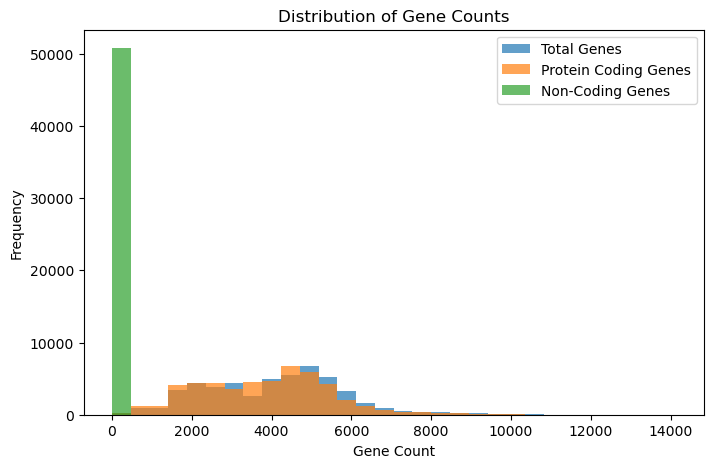

In [10]:
df = annotated_summary
df[['total_gene_count', 'protein_coding_gene_count', 'non_coding_gene_count']].plot(
    kind='hist', bins=30, alpha=0.7, figsize=(8, 5), title='Distribution of Gene Counts'
)
plt.xlabel('Gene Count')
plt.ylabel('Frequency')
plt.legend(['Total Genes', 'Protein Coding Genes', 'Non-Coding Genes'])
plt.show()

b. Assembly Level Distribution

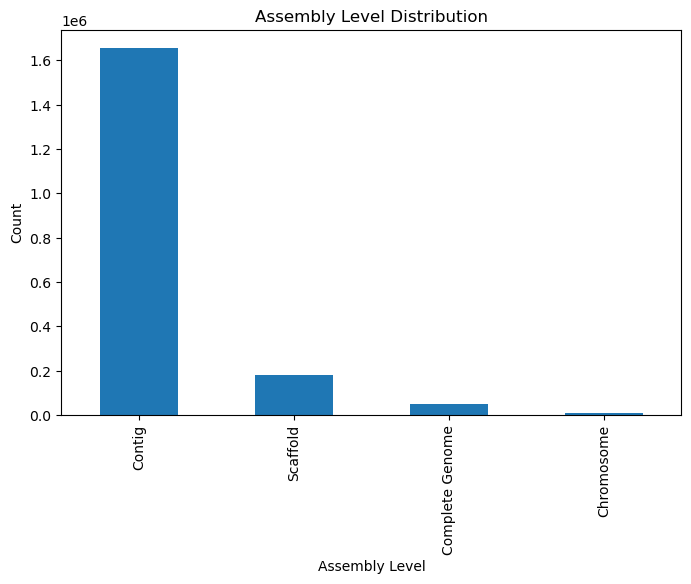

In [12]:
annotated_summary_['assembly_level'].value_counts().plot(
    kind='bar', title='Assembly Level Distribution', figsize=(8, 5)
)
plt.xlabel('Assembly Level')
plt.ylabel('Count')
plt.show()

c. Box Plot for Genome Size vs. Assembly Levels

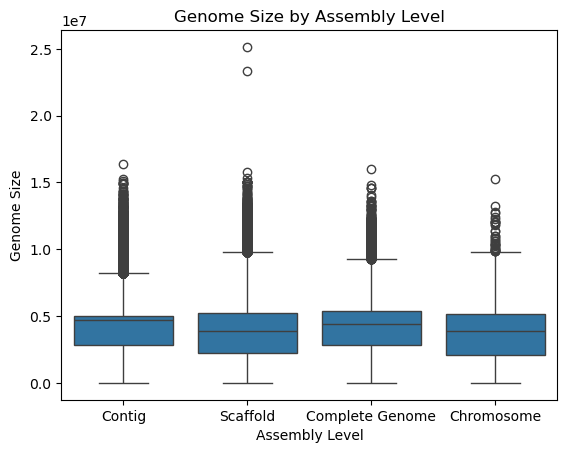

In [13]:
import seaborn as sns

sns.boxplot(data=annotated_summary_, x='assembly_level', y='genome_size')
plt.title('Genome Size by Assembly Level')
plt.xlabel('Assembly Level')
plt.ylabel('Genome Size')
plt.show()

In [ ]:
# END 